In [3]:
import json
import tensorflow as tf
from tensorflow.keras import layers, models

print("All libraries loaded")

All libraries loaded


In [4]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10

In [13]:
TRAIN_DIR = "archive (1)/Tomato/Train"
VAL_DIR = "archive (1)/Tomato/Val"
TEST_DIR = "archive (1)/Tomato/Test"

In [14]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Found 11108 files belonging to 6 classes.
Found 2495 files belonging to 6 classes.
Found 280 files belonging to 6 classes.
Classes: ['Bacterial Spot', 'Early Blight', 'Healthy', 'Late Blight', 'Septoria Leaf Spot', 'Yellow Leaf Curl Virus']
Number of classes: 6


In [15]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

In [16]:
base_model.trainable = False
print("Borrowed MobileNetV2 with", len(base_model.layers), "layers (all frozen for now)")

Borrowed MobileNetV2 with 154 layers (all frozen for now)


In [17]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = models.Model(inputs, outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [18]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [19]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

import numpy as np
# Save model and history
model.save("plant_model.keras")
np.save("training_history.npy", history.history)

print("Model saved successfully: plant_model.keras")

Epoch 1/10


c:\Users\HP\OneDrive\Desktop\project\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


348/348 ━━━━━━━━━━━━━━━━━━━━ 218s 609ms/step - accuracy: 0.7549 - loss: 0.6917 - val_accuracy: 0.8729 - val_loss: 0.3830
Epoch 2/10
348/348 ━━━━━━━━━━━━━━━━━━━━ 154s 441ms/step - accuracy: 0.8723 - loss: 0.3746 - val_accuracy: 0.8930 - val_loss: 0.3068
Epoch 3/10
348/348 ━━━━━━━━━━━━━━━━━━━━ 280s 665ms/step - accuracy: 0.8872 - loss: 0.3230 - val_accuracy: 0.9022 - val_loss: 0.2780
Epoch 4/10
348/348 ━━━━━━━━━━━━━━━━━━━━ 181s 519ms/step - accuracy: 0.8962 - loss: 0.2959 - val_accuracy: 0.9134 - val_loss: 0.2509
Epoch 5/10
348/348 ━━━━━━━━━━━━━━━━━━━━ 158s 454ms/step - accuracy: 0.9000 - loss: 0.2825 - val_accuracy: 0.9130 - val_loss: 0.2477
Epoch 6/10
348/348 ━━━━━━━━━━━━━━━━━━━━ 164s 471ms/step - accuracy: 0.9035 - loss: 0.2776 - val_accuracy: 0.9118 - val_loss: 0.2428
Epoch 7/10
348/348 ━━━━━━━━━━━━━━━━━━━━ 172s 494ms/step - accuracy: 0.9093 - loss: 0.2540 - val_accuracy: 0.9174 - val_loss: 0.2314
Epoch 8/10
348/348 ━━━━━━━━━━━━━━━━━━━━ 193s 556ms/step - accuracy: 0.9064 - loss: 0.25

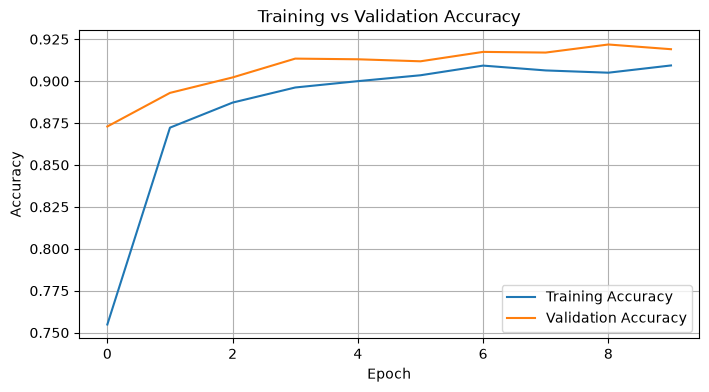

9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 305ms/step - accuracy: 0.9286 - loss: 0.2264
Final test accuracy: 92.9%


In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

loss, accuracy = model.evaluate(test_ds)
print(f"Final test accuracy: {accuracy * 100:.1f}%")